**Regresíon: Pronostico de Ingreso Mensual**

Pregunta: ¿Cuál será el ingreso mensual de la tienda?

*Objetivo: Predecir el importe (monto total) de una venta futura.*

 Regresión Lineal: Es el modelo base.

 Random Forest Regressor (Ensamble): Es un modelo avanzado, que funciona bien con el objetivo, considerando que en una situación en la que "Cordoba" sea una ciudad en la que se gasta más, pero solo con "Tarjeta", éste puede entrenar estos tipos de datos de manera robusta y dar mejores resultados en datos de ventas minoristas como es nuestro caso. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.style.use('ggplot')

# 1. Cargamos base de datos limpia

df = pd.read_csv(r'C:\Users\Goddess\Documents\FundamentosIA\Entrega 3/Tabla_Maestra_limpia.csv')


print(f"Datos cargados: {df.shape[0]} registros y {df.shape[1]} columnas.")
df.head(3)

Datos cargados: 343 registros y 16 columnas.


,id_producto,nombre_producto,cantidad,precio_unitario,importe,fecha,email,medio_pago,anio,mes,trimestre,nombre_mes,ciudad,fecha_alta,categoria,dias_desde_alta
0,90,toallas húmedas x50,1,2902,2902,2024-06-19,guadalupe.romero@mail.com,tarjeta,2024,6,2,June,carlos paz,2023-03-03,higiene personal,474
1,82,aceitunas negras 200g,5,2394,11970,2024-03-17,olivia.gomez@mail.com,qr,2024,3,1,March,rio cuarto,2023-02-18,alimentos,393
2,39,helado vainilla 1l,5,469,2345,2024-03-17,olivia.gomez@mail.com,qr,2024,3,1,March,rio cuarto,2023-02-18,alimentos,393


In [2]:
# 2.Variables

# Columnas para la predicción
caracteristicas = ['dias_desde_alta', 'precio_unitario', 'cantidad', 'categoria', 'ciudad', 'medio_pago']
objetivo = 'importe'

# Definimos X e y
X = df[caracteristicas]
y = df[objetivo]

# 3. Transformación de datos categóricos (Encoding)
# de texto a columnas binarias (0 y 1)
X = pd.get_dummies(X, columns=['categoria', 'ciudad', 'medio_pago'], drop_first=True)

print("------------ Estructura de X procesada -------------")
print(X.head())

------------ Estructura de X procesada -------------
   dias_desde_alta  precio_unitario  cantidad  categoria_higiene personal  \
0              474             2902         1                        True   
1              393             2394         5                       False   
2              393              469         5                       False   
3              393             4061         2                       False   
4              393             2069         1                       False   

   categoria_limpieza  ciudad_carlos paz  ciudad_cordoba  ciudad_mendiolaza  \
0               False               True           False              False   
1               False              False           False              False   
2               False              False           False              False   
3               False              False           False              False   
4               False              False           False              False   

   ciudad

In [3]:
# 4. División del dataset
# Aquí entrenamos tanto la Regresión Lineal como el Random Forest para comparar.
# Usaremos 80% para entrenar y 20% para probar la efectividad
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Entrenamiento: {X_train.shape[0]} registros")
print(f"Prueba: {X_test.shape[0]} registros")

Entrenamiento: 274 registros
Prueba: 69 registros


In [4]:
# MODELO A: Regresión Lineal
lineal = LinearRegression()
lineal.fit(X_train, y_train)
y_pred_lineal = lineal.predict(X_test)

# MODELO B: Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)


Para este analisis usamos metricas estándar de sklear.metrics para regresión.
* R2, coeficiente de determinación, nos dice qué porcentaje de variabilidad del ingreso explica nuestro modelo (1.0 es perfecto y 0.0 es malo).
* MAE, error Absoluto Medio nos da un promedio de '¿Cuantos pesos estamos equivocados?
* MSE, Error Cuatratico Medio, penaliza los errores grandes (outliers).


- Resultados para: Regresión Lineal -
R2 Score (Precisión general): 0.8340
MAE (Error promedio en $): $1243.20
RMSE (Error cuadrático): 1691.25
------------------------------
- Resultados para: Random Forest -
R2 Score (Precisión general): 0.9915
MAE (Error promedio en $): $201.27
RMSE (Error cuadrático): 382.86
------------------------------


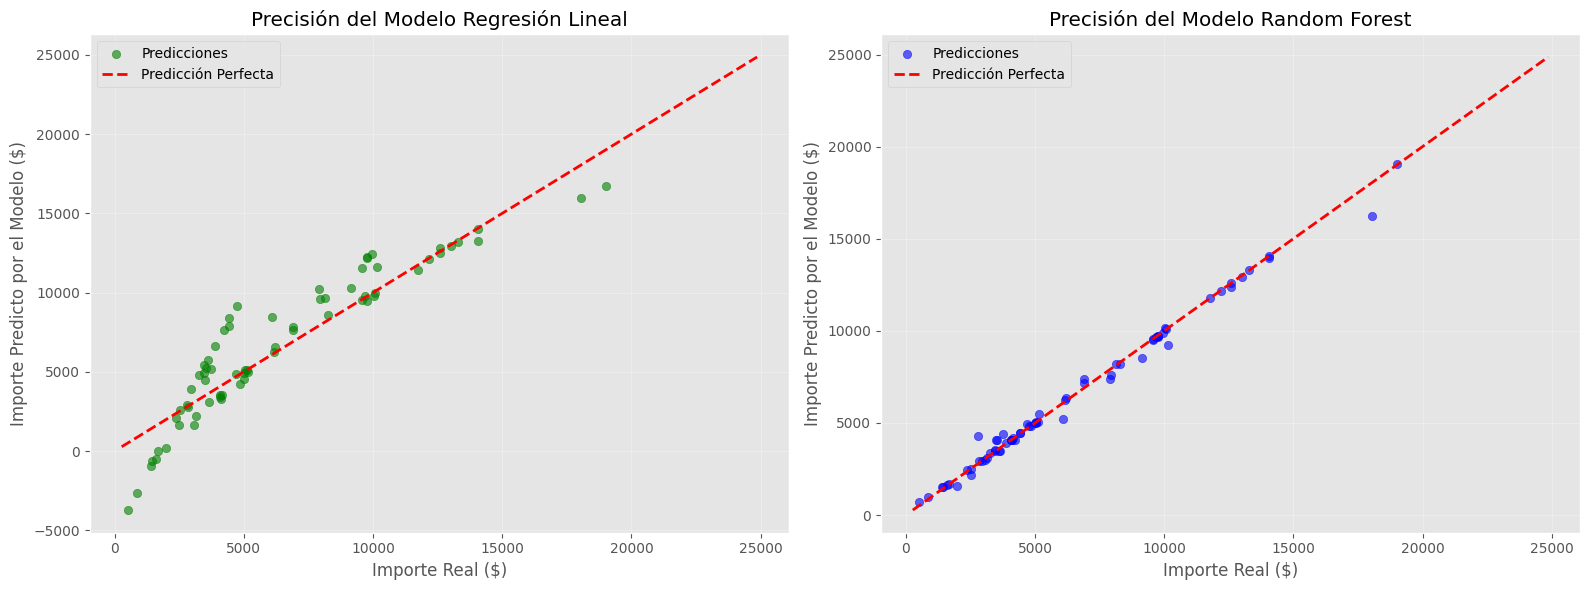

In [5]:
def evaluar_modelo(nombre, y_real, y_pred):
    r2 = r2_score(y_real, y_pred)
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    
    print(f"- Resultados para: {nombre} -")
    print(f"R2 Score (Precisión general): {r2:.4f}")
    print(f"MAE (Error promedio en $): ${mae:.2f}")
    print(f"RMSE (Error cuadrático): {rmse:.2f}")
    print("-" * 30)

# Evaluamos ambos
evaluar_modelo("Regresión Lineal", y_test, y_pred_lineal)
evaluar_modelo("Random Forest", y_test, y_pred_rf)

# Gráfico comparativo: Real vs Predicto (Ambos Modelos)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Regresión Lineal
axes[0].scatter(y_test, y_pred_lineal, alpha=0.6, color='green', label='Predicciones')
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Predicción Perfecta')
axes[0].set_xlabel('Importe Real ($)')
axes[0].set_ylabel('Importe Predicto por el Modelo ($)')
axes[0].set_title('Precisión del Modelo Regresión Lineal')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Random Forest
axes[1].scatter(y_test, y_pred_rf, alpha=0.6, color='blue', label='Predicciones')
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Predicción Perfecta')
axes[1].set_xlabel('Importe Real ($)')
axes[1].set_ylabel('Importe Predicto por el Modelo ($)')
axes[1].set_title('Precisión del Modelo Random Forest')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Siguiendo el hilo de nuestro analisis...

Con nuestra regresión lineal anterior respondemos a "cuánto" se va a vender. 
Ahora usaremos Regresión Logistica, con el fin de clasificar la 'Categoria' del producto vendido (ej Alimentos,Limpieza, etc)

-- Clasificación: Regresión Logística --
Mapeo etiquetas: {0: 'alimentos', 1: 'higiene personal', 2: 'limpieza'}
Precisión: 0.8405797101449275

Reporte de clasificación:
                   precision    recall  f1-score   support

       alimentos       0.84      1.00      0.91        58
higiene personal       0.00      0.00      0.00         6
        limpieza       0.00      0.00      0.00         5

        accuracy                           0.84        69
       macro avg       0.28      0.33      0.30        69
    weighted avg       0.71      0.84      0.77        69



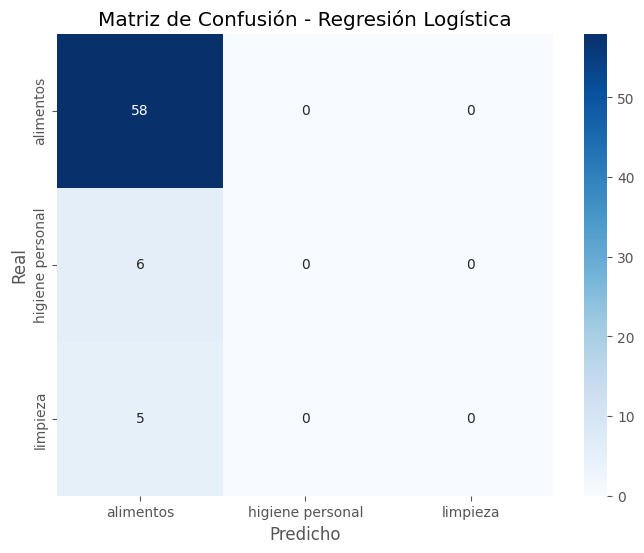

In [6]:
print(f"-- Clasificación: Regresión Logística --")

# 5. Clasificación: Predecir 'categoria' con Regresión Logística
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Definimos características para la clasificación (no incluimos 'categoria' como input)
features_clf = ['dias_desde_alta', 'precio_unitario', 'cantidad', 'ciudad', 'medio_pago']
X_clf = df[features_clf].copy()
y_clf = df['categoria'].copy()

# Encoding: variables categóricas en X y codificación de etiquetas para Y
X_clf = pd.get_dummies(X_clf, columns=['ciudad', 'medio_pago'], drop_first=True)
le = LabelEncoder()
y_enc = le.fit_transform(y_clf)

# División del dataset (estratificamos por clase para mantener proporciones)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_enc, test_size=0.2, random_state=42, stratify=y_enc
)

# Escalado de variables numéricas
scaler = StandardScaler()
num_cols = ['dias_desde_alta', 'precio_unitario', 'cantidad']
Xc_train[num_cols] = scaler.fit_transform(Xc_train[num_cols])
Xc_test[num_cols] = scaler.transform(Xc_test[num_cols])

# Entrenamiento: Regresión Logística multinomial
logreg = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
logreg.fit(Xc_train, yc_train)
yc_pred = logreg.predict(Xc_test)

# Evaluación
print("Mapeo etiquetas:", dict(enumerate(le.classes_)))
print("Precisión:", accuracy_score(yc_test, yc_pred))
print("\nReporte de clasificación:\n", classification_report(yc_test, yc_pred, target_names=le.classes_, zero_division=0))

# Matriz de confusión
cm = confusion_matrix(yc_test, yc_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.title('Matriz de Confusión - Regresión Logística')
plt.show()


### Hasta el momento, observamos que el modelo de Regresión Lineal alcanza una precisión del 80%; sin embargo, muestra métricas de error (MAE y RMSE) más elevadas en comparación con el modelo de Random Forest, el cual ofrece una capacidad predictiva significativamente superior.

### Asimismo, la Regresión Logística (con una precisión de +80%) proyecta a la categoría 'Alimentos' como la de mayor venta futura. Dado esto, resulta pertinente analizar la probabilidad de que los clientes adquieran productos de otras categorías, como 'Limpieza', en sus próximas visitas.

--- PROPENSIÓN DE COMPRA: Predicción Binaria ---
Distribución de clases - Compró limpieza: 27 (7.9%)
No compró limpieza: 316 (92.1%)


--- Regresión Logística ---
Accuracy:  0.9275
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
ROC-AUC:   0.5781

--- Random Forest ---
Accuracy:  0.9275
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
ROC-AUC:   0.7344



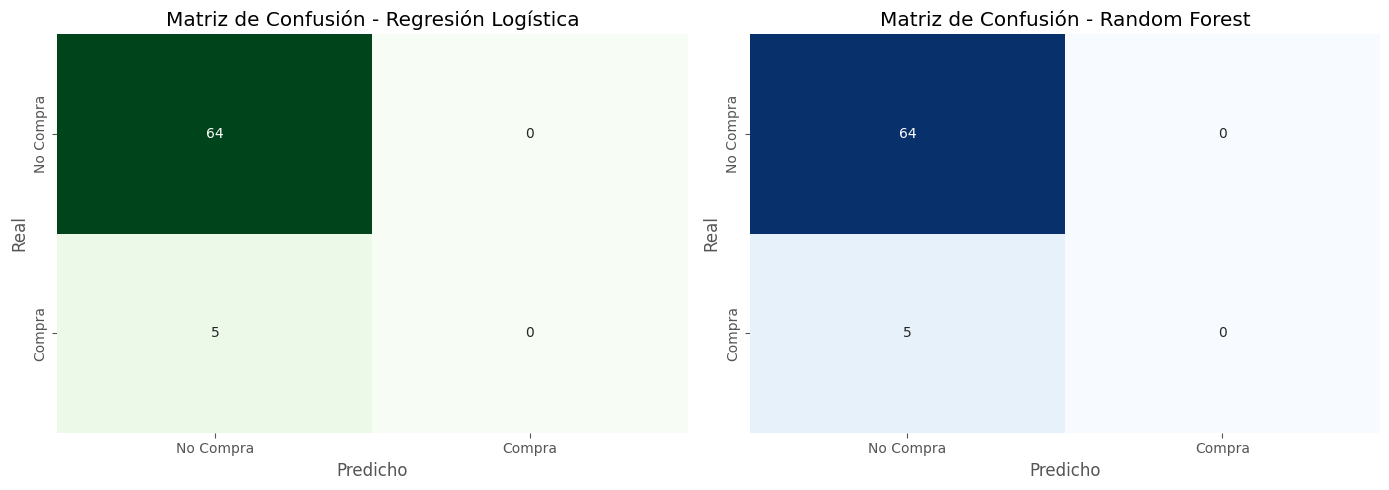

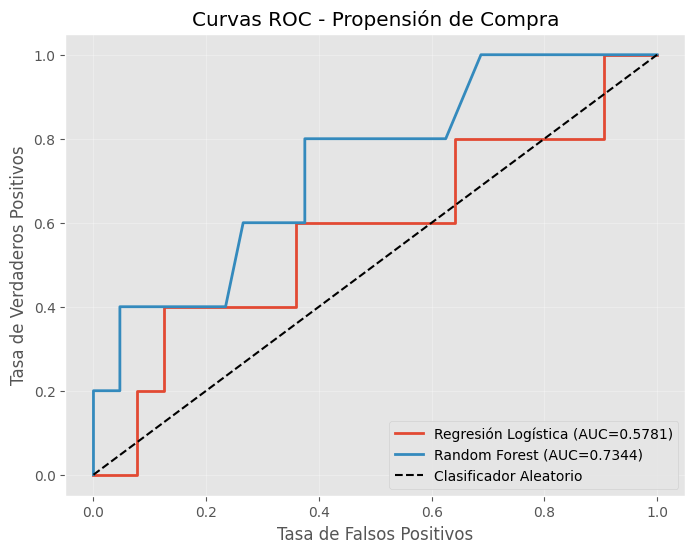

In [7]:
# 6. Propensión de Compra: ¿Comprará 'limpieza' en su próxima visita?
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier

# Crear variable binaria: 1 si compró 'limpieza', 0 si no
df['compro_limpieza'] = (df['categoria'] == 'limpieza').astype(int)

# Datos para la predicción
features_prop = ['dias_desde_alta', 'precio_unitario', 'cantidad', 'ciudad', 'medio_pago']
X_prop = df[features_prop].copy()
y_prop = df['compro_limpieza'].copy()

# Encoding de variables categóricas
X_prop = pd.get_dummies(X_prop, columns=['ciudad', 'medio_pago'], drop_first=True)

# División del dataset
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_prop, y_prop, test_size=0.2, random_state=42, stratify=y_prop)

# Escalado de variables numéricas
scaler_prop = StandardScaler()
num_cols_prop = ['dias_desde_alta', 'precio_unitario', 'cantidad']
Xp_train[num_cols_prop] = scaler_prop.fit_transform(Xp_train[num_cols_prop])
Xp_test[num_cols_prop] = scaler_prop.transform(Xp_test[num_cols_prop])

print("--- PROPENSIÓN DE COMPRA: Predicción Binaria ---")
print(f"Distribución de clases - Compró limpieza: {y_prop.sum()} ({y_prop.sum()/len(y_prop)*100:.1f}%)")
print(f"No compró limpieza: {(1-y_prop).sum()} ({(1-y_prop).sum()/len(y_prop)*100:.1f}%)")
print("\n")

# MODELO 1: Regresión Logística Binaria
logreg_prop = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
logreg_prop.fit(Xp_train, yp_train)
yp_pred_logistic = logreg_prop.predict(Xp_test)
yp_proba_logistic = logreg_prop.predict_proba(Xp_test)[:, 1]

# MODELO 2: Random Forest
rf_prop = RandomForestClassifier(n_estimators=100, random_state=42)
rf_prop.fit(Xp_train, yp_train)
yp_pred_rf = rf_prop.predict(Xp_test)
yp_proba_rf = rf_prop.predict_proba(Xp_test)[:, 1]

# Función de evaluación
def evaluar_clasificacion_binaria(nombre, y_real, y_pred, y_proba):
    acc = accuracy_score(y_real, y_pred)
    prec = precision_score(y_real, y_pred, zero_division=0)
    rec = recall_score(y_real, y_pred, zero_division=0)
    f1 = f1_score(y_real, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_real, y_proba)
    
    print(f"--- {nombre} ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print()

evaluar_clasificacion_binaria("Regresión Logística", yp_test, yp_pred_logistic, yp_proba_logistic)
evaluar_clasificacion_binaria("Random Forest", yp_test, yp_pred_rf, yp_proba_rf)

# Matrices de confusión juntas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_logistic = confusion_matrix(yp_test, yp_pred_logistic)
sns.heatmap(cm_logistic, annot=True, fmt='d', cmap='Greens', ax=axes[0], cbar=False)
axes[0].set_xlabel('Predicho')
axes[0].set_ylabel('Real')
axes[0].set_title('Matriz de Confusión - Regresión Logística')
axes[0].set_xticklabels(['No Compra', 'Compra'])
axes[0].set_yticklabels(['No Compra', 'Compra'])

cm_rf = confusion_matrix(yp_test, yp_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_xlabel('Predicho')
axes[1].set_ylabel('Real')
axes[1].set_title('Matriz de Confusión - Random Forest')
axes[1].set_xticklabels(['No Compra', 'Compra'])
axes[1].set_yticklabels(['No Compra', 'Compra'])

plt.tight_layout()
plt.show()

# Curvas ROC
fpr_logistic, tpr_logistic, _ = roc_curve(yp_test, yp_proba_logistic)
fpr_rf, tpr_rf, _ = roc_curve(yp_test, yp_proba_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_logistic, tpr_logistic, label=f'Regresión Logística (AUC={roc_auc_score(yp_test, yp_proba_logistic):.4f})', lw=2)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC={roc_auc_score(yp_test, yp_proba_rf):.4f})', lw=2)
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curvas ROC - Propensión de Compra')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

### Ambos modelos tienen desbalance de clases severo (solo 7.9% con compra)
### Random Forest supera a Regresión Logística (AUC: 0.73 vs 0.58)
### Las matrices de confusión muestran que ambos predicen "No Compra" para casi todo